In [43]:
#Primero hago los imports basicos.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
#creamos el dataframe con el cvs

df = pd.read_csv("../data/data.csv")
df

,COUNTRY,CODE_TIME,TIME,YEAR,MONTH,MONTH_NAME,PRODUCT,VALUE,DISPLAY_ORDER,yearToDate,previousYearToDate,share
0,Australia,JAN2010,January 2010,2010,1,January,Hydro,990.728000,1,1.647189e+04,NaN,0.047771
1,Australia,JAN2010,January 2010,2010,1,January,Wind,409.469000,2,4.940909e+03,NaN,0.019744
2,Australia,JAN2010,January 2010,2010,1,January,Solar,49.216000,3,9.082380e+02,NaN,0.002373
3,Australia,JAN2010,January 2010,2010,1,January,Geothermal,0.083000,4,9.960000e-01,NaN,0.000004
4,Australia,JAN2010,January 2010,2010,1,January,Total combustible fuels,19289.730000,7,2.143030e+05,NaN,0.930108
...,...,...,...,...,...,...,...,...,...,...,...,...
181910,United States,DEC2022,December 2022,2022,12,December,Non-renewables,292417.548132,23,3.355042e+06,3.320634e+06,0.791164
181911,United States,DEC2022,December 2022,2022,12,December,Others,8017.840957,24,5.393606e+04,4.899452e+04,0.021693
181912,United States,DEC2022,December 2022,2022,12,December,Other renewables aggregated,6133.265943,25,7.100997e+04,7.242158e+04,0.016594
181913,United States,DEC2022,December 2022,2022,12,December,Low carbon,146425.474534,26,1.749805e+06,1.670531e+06,0.396168


In [45]:
#Lo inspeccionamos un poco
df.info() #tipos y cantidad de datos
df.describe() #devuelve un datafrae con un un resumen estadistico de cada calumna


<class 'pandas.DataFrame'>
RangeIndex: 181915 entries, 0 to 181914
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   COUNTRY             181915 non-null  str    
 1   CODE_TIME           181915 non-null  str    
 2   TIME                181915 non-null  str    
 3   YEAR                181915 non-null  int64  
 4   MONTH               181915 non-null  int64  
 5   MONTH_NAME          181915 non-null  str    
 6   PRODUCT             181915 non-null  str    
 7   VALUE               181915 non-null  float64
 8   DISPLAY_ORDER       181915 non-null  int64  
 9   yearToDate          181915 non-null  float64
 10  previousYearToDate  164810 non-null  float64
 11  share               181915 non-null  float64
dtypes: float64(4), int64(3), str(5)
memory usage: 16.7 MB


,YEAR,MONTH,VALUE,DISPLAY_ORDER,yearToDate,previousYearToDate,share
count,181915.000000,181915.000000,1.819150e+05,181915.000000,1.819150e+05,1.648100e+05,181915.000000
mean,2016.456818,6.498145,2.091292e+04,14.418410,2.509544e+05,1.382083e+05,0.289057
std,3.657532,3.452288,8.584724e+04,7.819235,1.026864e+06,6.383465e+05,0.427347
min,2010.000000,1.000000,-6.852344e+03,1.000000,-6.667000e+04,-6.667000e+04,-4.649269
25%,2013.000000,3.000000,6.685189e+01,8.000000,8.831870e+02,3.988967e+02,0.009907
50%,2017.000000,6.000000,7.663990e+02,15.000000,9.558855e+03,4.356565e+03,0.082530
75%,2020.000000,9.000000,4.989495e+03,21.000000,5.927517e+04,3.025087e+04,0.511302
max,2022.000000,12.000000,1.001529e+06,27.000000,1.082156e+07,1.082156e+07,5.649269


In [46]:
df.head() #vemos las primeras filas del dataframe
df.columns

Index(['COUNTRY', 'CODE_TIME', 'TIME', 'YEAR', 'MONTH', 'MONTH_NAME',
       'PRODUCT', 'VALUE', 'DISPLAY_ORDER', 'yearToDate', 'previousYearToDate',
       'share'],
      dtype='str')

In [47]:
#Como dato clave para la hipotesis es el tipo de producción electrica, debo ver todas las posibilidades y clasificarlas
df['PRODUCT'].unique() #con esto veo cada tipo dentro de la columna


<StringArray>
[                           'Hydro',                             'Wind',
                            'Solar',                       'Geothermal',
          'Total combustible fuels',                             'Coal',
                              'Oil',                      'Natural gas',
           'Combustible renewables',       'Net electricity production',
             'Electricity supplied',          'Used for pumped storage',
              'Distribution losses',                'Final consumption',
                       'Renewables',                   'Non-renewables',
                           'Others',      'Other renewables aggregated',
                       'Low carbon',                     'Fossil fuels',
 'Other combustible non-renewables',                    'Not specified',
                    'Total imports',                    'Total exports',
                'Electricity trade',                          'Nuclear',
                 'Other renewables']


In [48]:
#Crearemos la columna fecha para trabajar mas comodo con el factor tiempo
df['fecha'] = pd.to_datetime(
    df['YEAR'].astype(str) + '-' + df['MONTH'].astype(str) + '-01', errors='coerce'
)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 181915 entries, 0 to 181914
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   COUNTRY             181915 non-null  str           
 1   CODE_TIME           181915 non-null  str           
 2   TIME                181915 non-null  str           
 3   YEAR                181915 non-null  int64         
 4   MONTH               181915 non-null  int64         
 5   MONTH_NAME          181915 non-null  str           
 6   PRODUCT             181915 non-null  str           
 7   VALUE               181915 non-null  float64       
 8   DISPLAY_ORDER       181915 non-null  int64         
 9   yearToDate          181915 non-null  float64       
 10  previousYearToDate  164810 non-null  float64       
 11  share               181915 non-null  float64       
 12  fecha               181915 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(4), int64(

In [49]:
#vamos a crear una nueva columna que clasificará los productos segun su valor en:

#sources o fuentes es la fuente específica del producto
sources = {'Hydro', 'Wind', 'Solar', 'Geothermal',
    'Combustible renewables', 'Other renewables',
    'Other renewables aggregated', 'Renewables',
    'Coal', 'Oil', 'Natural gas', 'Nuclear',
    'Fossil fuels', 'Other combustible non-renewables',
    'Non-renewables'}

#Aggregate sera una categoria que puede agrupar varias fuentes

aggregates = {'Renewables', 'Non-renewables', 'Other renewables',
    'Other renewables aggregated', 'Fossil fuels',
    'Low carbon', 'Other combustible non-renewables'}

balances = {
    'Total combustible fuels', 'Net electricity production',
    'Electricity supplied', 'Used for pumped storage',
    'Distribution losses', 'Final consumption',
    'Others', 'Not specified', 'Total imports',
    'Total exports', 'Electricity trade'
}

def classify_category(product):
    if product in sources:
        return 'Source'
    elif product in aggregates:
        return 'Aggregate'
    else:
        return 'Balance'

df['CATEGORY'] = df['PRODUCT'].apply(classify_category)
df['CATEGORY'].value_counts()   

CATEGORY
Source       99321
Balance      75262
Aggregate     7332
Name: count, dtype: int64

In [50]:
#Ahora las voy a separar en renovables, no renovables o mixtas

renewables = {
    'Hydro', 'Wind', 'Solar', 'Geothermal',
    'Combustible renewables', 'Other renewables',
    'Other renewables aggregated', 'Renewables'
}

non_renewables = {
    'Coal', 'Oil', 'Natural gas', 'Nuclear',
    'Fossil fuels', 'Other combustible non-renewables',
    'Non-renewables'
}

def classify_renewable(product):
    if product in renewables:
        return 'Renewable'
    elif product in non_renewables:
        return 'Non-renewable'
    else:
        return 'Mixed/Other'

df['RENEWABLE'] = df['PRODUCT'].apply(classify_renewable)
df['RENEWABLE'].value_counts()


RENEWABLE
Mixed/Other      82594
Renewable        51683
Non-renewable    47638
Name: count, dtype: int64

In [51]:
#Reviso que esté funcionando todo bien, .sample() devuelve una cantidad de lineas pero al azar, similar a head o tail
df[['PRODUCT', 'CATEGORY', 'RENEWABLE']].sample(10)

,PRODUCT,CATEGORY,RENEWABLE
96746,Hydro,Source,Renewable
100184,Wind,Source,Renewable
106548,Coal,Source,Non-renewable
91424,Renewables,Source,Renewable
123642,Combustible renewables,Source,Renewable
76583,Hydro,Source,Renewable
31671,Coal,Source,Non-renewable
162059,Total imports,Balance,Mixed/Other
141113,Not specified,Balance,Mixed/Other
114527,Renewables,Source,Renewable


In [52]:
df = df.drop(columns=['CODE_TIME', 'TIME', 'MONTH_NAME', 'DISPLAY_ORDER'])


In [53]:
#ahora quiero agruparlos por continente
df['COUNTRY'].unique()

europa = [
    'Austria','Belgium','Czech Republic','Denmark','Estonia','Finland','France',
    'Germany','Greece','Hungary','Iceland','Ireland','Italy','Latvia','Lithuania',
    'Luxembourg','Netherlands','Norway','Poland','Portugal','Republic of Turkiye',
    'Slovak Republic','Slovenia','Spain','Sweden','Switzerland','United Kingdom',
    'Bulgaria','Croatia','Cyprus','Malta','North Macedonia','Romania','Serbia'
]

america = [
    'Canada','Chile','Mexico','United States','Colombia','Argentina','Brazil','Costa Rica'
]

asia = ['Japan','Korea','India']

oceania = ['Australia','New Zealand']

grupos = [
    'IEA Total','OECD Americas','OECD Asia Oceania','OECD Europe','OECD Total'
]

def asignar_continente(country):
    if country in europa:
        return 'Europe'
    elif country in america:
        return 'America'
    elif country in asia:
        return 'Asia'
    elif country in oceania:
        return 'Oceania'
    elif country in grupos:
        return 'Group'
    else:
        return 'Unknown'

df['CONTINENT'] = df['COUNTRY'].apply(asignar_continente)


In [54]:
#comprobamos que funciona

df['CONTINENT'].unique()
df[['COUNTRY','CONTINENT']].sample(20)




,COUNTRY,CONTINENT
36345,Norway,Europe
81755,India,Asia
27903,Sweden,Europe
30675,Portugal,Europe
164611,Lithuania,Europe
1420,Latvia,Europe
177777,Iceland,Europe
107538,Czech Republic,Europe
100386,Spain,Europe
153773,Poland,Europe


In [55]:
#agregaremos el GDP de cada pais para poder trabajar con el
gdp_dict = {
    # Economías de escala mayor (trillones → miles de millones)
    'United States': 32640,
    'Germany': 5470,
    'Japan': 4340,
    'United Kingdom': 4270,
    'India': 4060,
    'France': 3550,
    'Italy': 2700,
    'Brazil': 2650,
    'Canada': 2490,
    'Korea': 2250,
    'Mexico': 2180,
    'Australia': 2110,
    'Spain': 2090,
    'Republic of Turkiye': 1820,
    'Netherlands': 1420,
    'Switzerland': 1140,
    'Poland': 1130,

    # Economías media-alta (billones)
    'Belgium': 772.7,
    'Argentina': 768.2,
    'Sweden': 745.1,
    'Ireland': 709.9,
    'Norway': 651.7,
    'Austria': 616.9,
    'Colombia': 572.7,
    'Denmark': 499.3,
    'Romania': 470.1,
    'Czech Republic': 427.9,
    'Chile': 402.2,
    'Portugal': 375.2,
    'Finland': 338.5,
    'Greece': 304.6,
    'New Zealand': 273.4,
    'Hungary': 265.9,

    # Economías media-baja
    'Slovak Republic': 168.9,
    'Bulgaria': 146.5,
    'Croatia': 116.5,
    'Serbia': 112.0,
    'Costa Rica': 109.9,
    'Slovenia': 86.7,
    'Lithuania': 80.0,
    'Luxembourg': 78.0,
    'Latvia': 53.7,
    'Estonia': 51.6,
    'Cyprus': 45.1,
    'Iceland': 43.8,
    'North Macedonia': 15.0,
    'Malta': 14.0
}

#creamos la columna GDP con un map
df['GDP'] = df['COUNTRY'].map(gdp_dict)
#nuevamente reviso que esté todo en orden
df[['COUNTRY', 'GDP']].drop_duplicates().sort_values('GDP', ascending=False)


,COUNTRY,GDP
940,United States,32640.0
233,Germany,5470.0
393,Japan,4340.0
913,United Kingdom,4270.0
58811,India,4060.0
207,France,3550.0
368,Italy,2700.0
58426,Brazil,2650.0
70,Canada,2490.0
416,Korea,2250.0


In [56]:
#Ahora quiero calcular si ha habido crecimiento o no en el uso de energias renovables a lo largo de los años por pais

#hacemos un df solo de energias renovables
df_ren = df[df['RENEWABLE'] == 'Renewable']

#y uno para el conteo anual de energia producida
ren_yearly = df_ren.groupby(['COUNTRY', 'YEAR'])['VALUE'].sum().reset_index()
ren_yearly.head()

#calculamos si hubo aumento o disminución de uso de energias renovables por pais
ren_yearly['GROWTH'] = ren_yearly.groupby('COUNTRY')['VALUE'].diff()
#tambien puede ser util calcular el crecimiento porcentual
ren_yearly['GROWTH_PCT'] = ren_yearly.groupby('COUNTRY')['VALUE'].pct_change() * 100

ren_yearly

#si queremos ver crecimiento de un pais en particular
ren_yearly[ren_yearly['COUNTRY'] == 'Argentina']

#podemos mirar 
ren_yearly.sort_values('GROWTH_PCT', ascending=False)

growth_total = ren_yearly.groupby('COUNTRY').agg(
    FIRST_YEAR_VALUE=('VALUE', 'first'),
    LAST_YEAR_VALUE=('VALUE', 'last')
).reset_index()

growth_total

growth_total['TOTAL_GROWTH'] = growth_total['LAST_YEAR_VALUE'] - growth_total['FIRST_YEAR_VALUE']
growth_total['TOTAL_GROWTH_PCT'] = (
    growth_total['TOTAL_GROWTH'] / growth_total['FIRST_YEAR_VALUE']
) *100

growth_total_sorted = growth_total.sort_values('TOTAL_GROWTH_PCT', ascending=False)
growth_total_sorted.head(20)


,COUNTRY,FIRST_YEAR_VALUE,LAST_YEAR_VALUE,TOTAL_GROWTH,TOTAL_GROWTH_PCT
26,Korea,18636.041000,1.112389e+05,9.260282e+04,496.901790
50,United Kingdom,69594.794000,3.118357e+05,2.422409e+05,348.073302
32,Netherlands,28631.318000,1.056022e+05,7.697087e+04,268.834533
1,Australia,51511.542000,1.851973e+05,1.336857e+05,259.525815
23,Ireland,8075.153000,2.868984e+04,2.061469e+04,255.285422
40,Poland,27401.960000,8.032712e+04,5.292516e+04,193.143687
3,Belgium,19552.948000,5.376881e+04,3.421586e+04,174.990803
42,Republic of Turkiye,111309.895000,2.833949e+05,1.720850e+05,154.599953
14,Estonia,2611.959000,6.631690e+03,4.019731e+03,153.897189
30,Malta,209.864000,5.118920e+02,3.020280e+02,143.916061


C:\Users\hernu\AppData\Local\Temp\ipykernel_20696\1847824799.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


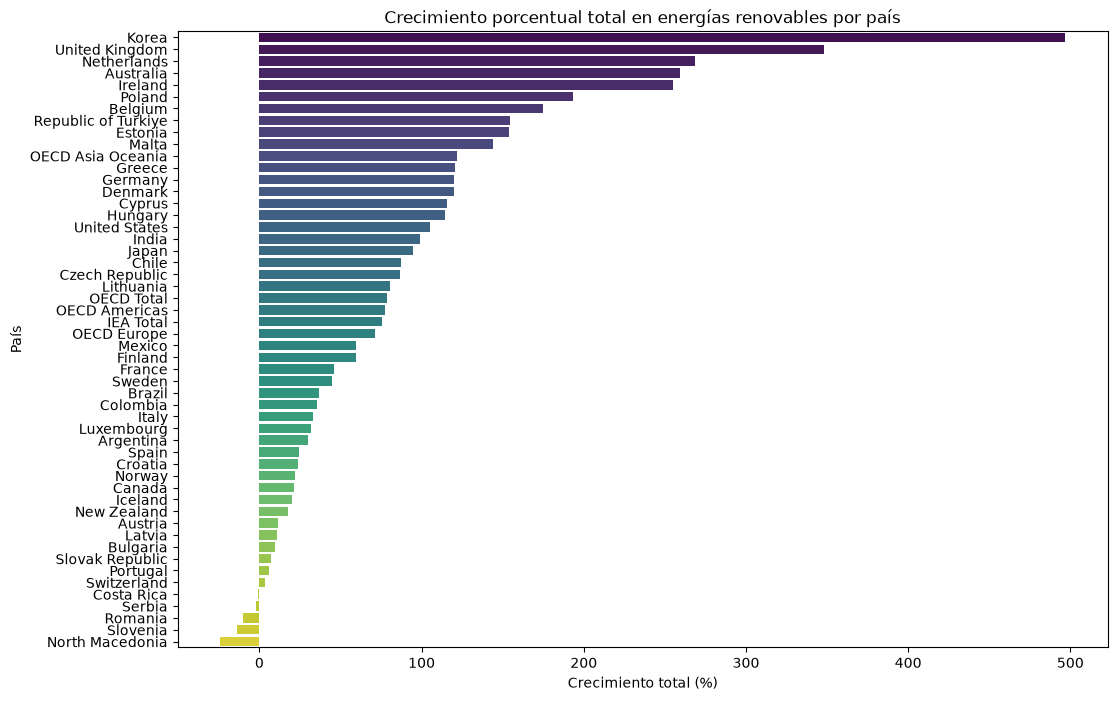

In [57]:
plt.figure(figsize=(12,8))
sns.barplot(
    data=growth_total_sorted,
    x='TOTAL_GROWTH_PCT',
    y='COUNTRY',
    palette='viridis'
)
plt.title("Crecimiento porcentual total en energías renovables por país")
plt.xlabel("Crecimiento total (%)")
plt.ylabel("País")
plt.show()


In [58]:
#podemos ver que pais tiene la mayor produccion de energia renovable sumando lo de toods los años
#primero sumamos las de cada pais
ren_total = df_ren.groupby('COUNTRY')['VALUE'].sum().reset_index()

#y las ordenamos
ren_total.sort_values('VALUE', ascending=False)


,COUNTRY,VALUE
39,OECD Total,7.448160e+07
20,IEA Total,7.170303e+07
38,OECD Europe,3.411775e+07
36,OECD Americas,3.300710e+07
51,United States,1.857951e+07
6,Canada,1.096862e+07
4,Brazil,8.224850e+06
37,OECD Asia Oceania,7.356757e+06
17,Germany,5.547020e+06
22,India,4.807996e+06


In [59]:
#Agrupo por país, año y tipo de energía
energy_by_type = df.groupby(['COUNTRY', 'YEAR', 'RENEWABLE'])['VALUE'].sum().reset_index()
energy_by_type.head(10)

#anual total por pais
total_by_year = df.groupby(['COUNTRY', 'YEAR'])['VALUE'].sum().reset_index()
total_by_year = total_by_year.rename(columns={'VALUE': 'TOTAL_YEAR_VALUE'})


merged = energy_by_type.merge(total_by_year, on=['COUNTRY', 'YEAR'])
merged.head(15)


,COUNTRY,YEAR,RENEWABLE,VALUE,TOTAL_YEAR_VALUE
0,Argentina,2015,Mixed/Other,573744.368000,947425.726000
1,Argentina,2015,Non-renewable,305425.703000,947425.726000
2,Argentina,2015,Renewable,68255.655000,947425.726000
3,Argentina,2016,Mixed/Other,578950.752000,958772.480000
4,Argentina,2016,Non-renewable,316654.683000,958772.480000
5,Argentina,2016,Renewable,63167.045000,958772.480000
6,Argentina,2017,Mixed/Other,566840.084000,942826.488000
7,Argentina,2017,Non-renewable,308098.428000,942826.488000
8,Argentina,2017,Renewable,67887.976000,942826.488000
9,Argentina,2018,Mixed/Other,565303.362511,942977.579673


In [60]:
#Voy a calcular el total de energias producida por cada pais

energy_total = df.groupby('COUNTRY')['VALUE'].sum().reset_index()
energy_total = energy_total.rename(columns={'VALUE': 'TOTAL_ENERGY'})

#Y ahora unimos con gdp
energy_gdp = energy_total.merge(
    df[['COUNTRY', 'GDP']].drop_duplicates(),
    on='COUNTRY'
)

#divdimos la cantidad de energía total por su gdp, para calcular cuanta energia producen en relacion a su pbi
energy_gdp['ENERGY_PER_GDP'] = energy_gdp['TOTAL_ENERGY'] / energy_gdp['GDP']

energy_gdp.sort_values('ENERGY_PER_GDP', ascending=False)



,COUNTRY,TOTAL_ENERGY,GDP,ENERGY_PER_GDP
21,Iceland,1.499897e+06,43.8,34244.213204
25,Japan,9.367340e+07,4340.0,21583.732769
26,Korea,4.683166e+07,2250.0,20814.070744
6,Canada,5.125470e+07,2490.0,20584.216959
34,North Macedonia,3.012701e+05,15.0,20084.670008
22,India,7.716980e+07,4060.0,19007.340390
14,Estonia,9.715635e+05,51.6,18828.749709
15,Finland,6.373295e+06,338.5,18828.051563
35,Norway,1.139089e+07,651.7,17478.737002
48,Sweden,1.297384e+07,745.1,17412.217422


C:\Users\hernu\AppData\Local\Temp\ipykernel_20696\3976323010.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


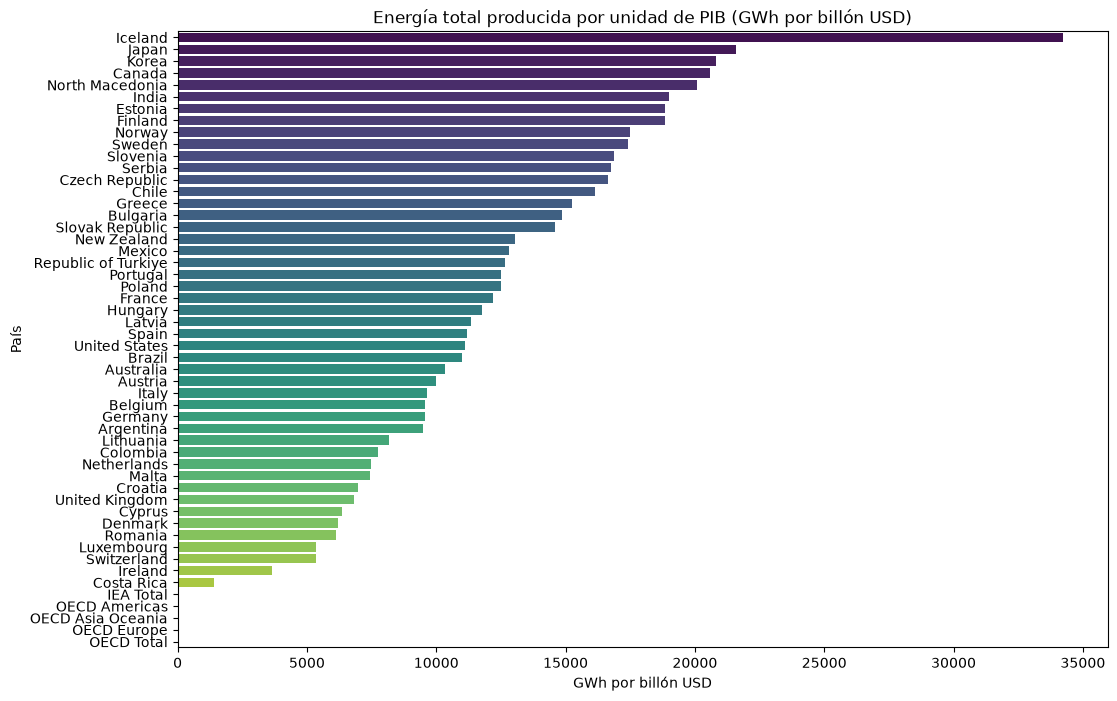

In [61]:
#Este gráfico mostrará los paises con mayore cantidad de energia (de cualquier tipo) generada en relacion a su pbi

plt.figure(figsize=(12,8))
sns.barplot(
    data=energy_gdp.sort_values('ENERGY_PER_GDP', ascending=False),
    x='ENERGY_PER_GDP',
    y='COUNTRY',
    palette='viridis'
)
plt.title("Energía total producida por unidad de PIB (GWh por billón USD)")
plt.xlabel("GWh por billón USD")
plt.ylabel("País")
plt.show()

In [62]:
#Teniendo la produccion total de energia en relacion al PBI
#Ahora si podemos filtrar por energías renovables y ver si solo son accesibles a paises con alto nivel adquisitivo

ren_total = df_ren.groupby('COUNTRY')['VALUE'].sum().reset_index()
ren_total = ren_total.rename(columns={'VALUE': 'TOTAL_REN'})

#unimos el gbp a las renovables totales por pais
ren_gdp = ren_total.merge(
    df[['COUNTRY', 'GDP']].drop_duplicates(),
    on='COUNTRY'
)

#dividimos la cantidad de energia renovable total de cada pais por su pbi, 
ren_gdp['REN_PER_GDP'] = ren_gdp['TOTAL_REN'] / ren_gdp['GDP']
ren_gdp.sort_values('REN_PER_GDP', ascending=False)

,COUNTRY,TOTAL_REN,GDP,REN_PER_GDP
21,Iceland,5.452902e+05,43.8,12449.548390
35,Norway,3.623999e+06,651.7,5560.839744
6,Canada,1.096862e+07,2490.0,4405.068708
33,New Zealand,9.939561e+05,273.4,3635.538187
48,Sweden,2.639174e+06,745.1,3542.039556
4,Brazil,8.224850e+06,2650.0,3103.716845
15,Finland,9.251729e+05,338.5,2733.154925
7,Chile,9.310956e+05,402.2,2315.006435
2,Austria,1.383312e+06,616.9,2242.359904
41,Portugal,7.810614e+05,375.2,2081.720279


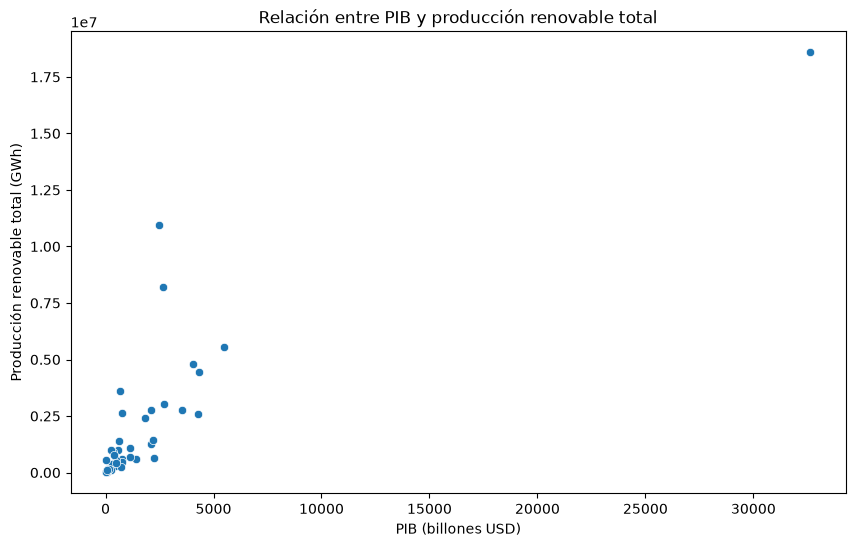

In [63]:
#
ren_gdp[['GDP', 'TOTAL_REN']].corr()

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=ren_gdp,
    x='GDP',
    y='TOTAL_REN'
)

plt.title("Relación entre PIB y producción renovable total")
plt.xlabel("PIB (billones USD)")
plt.ylabel("Producción renovable total (GWh)")
plt.show()

C:\Users\hernu\AppData\Local\Temp\ipykernel_20696\236199195.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


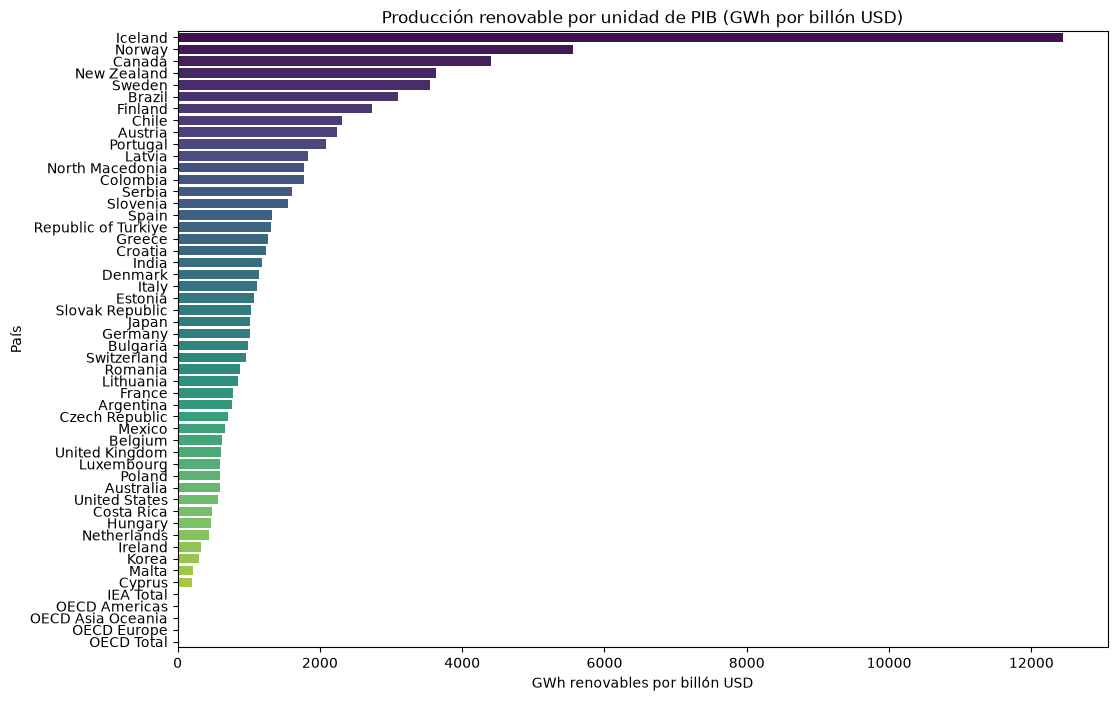

In [64]:
#este grafico es similar al que compara la energia producida/pbi, pero ahora solo de las renovables

plt.figure(figsize=(12,8))
sns.barplot(
    data=ren_gdp.sort_values('REN_PER_GDP', ascending=False),
    x='REN_PER_GDP',
    y='COUNTRY',
    palette='viridis'
)

plt.title("Producción renovable por unidad de PIB (GWh por billón USD)")
plt.xlabel("GWh renovables por billón USD")
plt.ylabel("País")
plt.show()


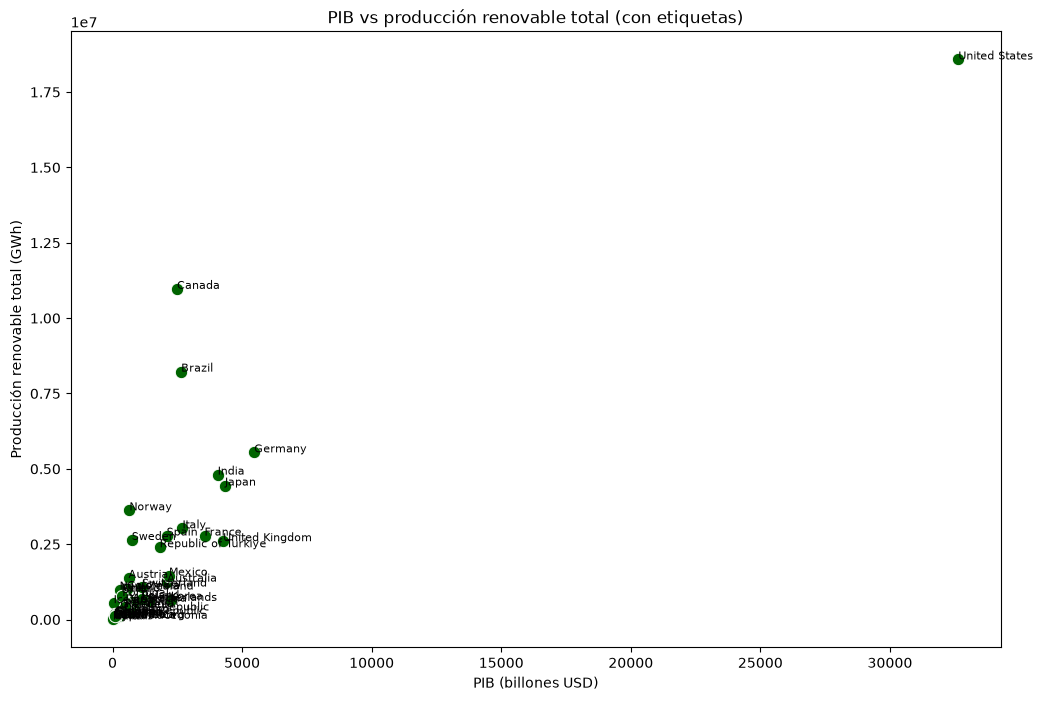

In [65]:
#Este grafico es mas de lo mismo pero no me convence como muestra los paises
#quería mostrar que no solo los paises con mucho poderio economico acceden a fuentes renovables, pero se ve feo así
plt.figure(figsize=(12,8))
sns.scatterplot(
    data=ren_gdp,
    x='GDP',
    y='TOTAL_REN',
    color='darkgreen',
    s=80
)

for i, row in ren_gdp.iterrows():
    plt.text(row['GDP'], row['TOTAL_REN'], row['COUNTRY'], fontsize=8)

plt.title("PIB vs producción renovable total (con etiquetas)")
plt.xlabel("PIB (billones USD)")
plt.ylabel("Producción renovable total (GWh)")
plt.show()


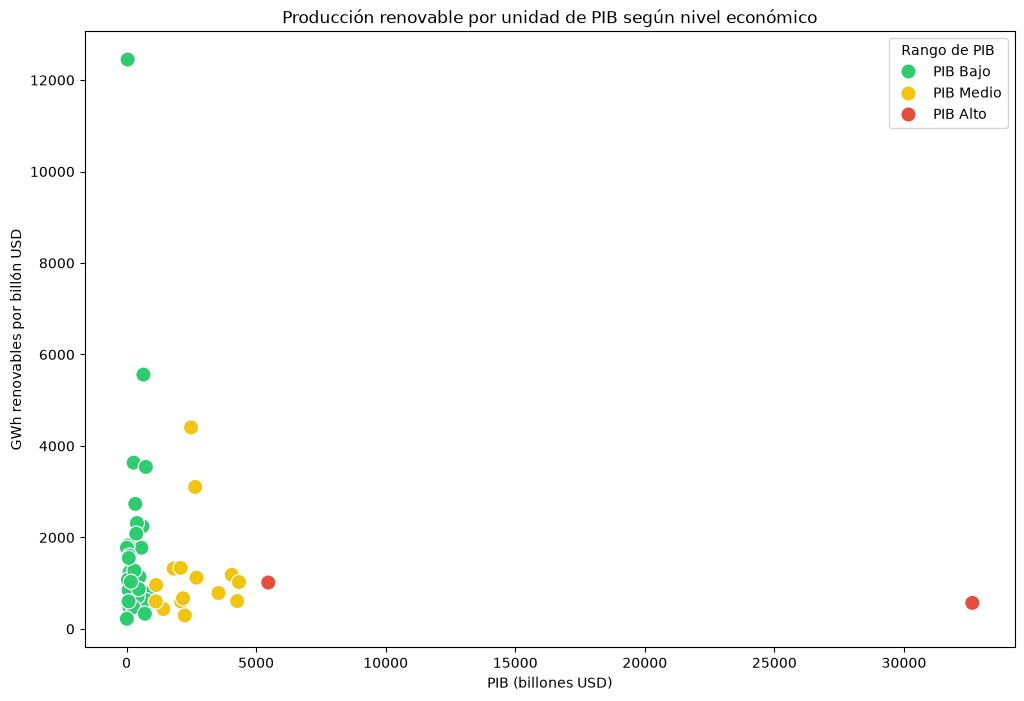

In [66]:
#Este es casi igual al anterior, pero agregué etiquetas de color segun el rangos económicos aplicados al gdp de cada pais

bins = [0, 1000, 5000, ren_gdp['GDP'].max()]
labels = ['PIB Bajo', 'PIB Medio', 'PIB Alto']

ren_gdp['GDP_RANGE'] = pd.cut(ren_gdp['GDP'], bins=bins, labels=labels)

plt.figure(figsize=(12,8))

sns.scatterplot(
    data=ren_gdp,
    x='GDP',
    y='REN_PER_GDP',
    hue='GDP_RANGE',
    palette=['#2ecc71', '#f1c40f', '#e74c3c'],  # verde, amarillo, rojo
    s=120
)

plt.title("Producción renovable por unidad de PIB según nivel económico")
plt.xlabel("PIB (billones USD)")
plt.ylabel("GWh renovables por billón USD")
plt.legend(title="Rango de PIB")
plt.show()


In [67]:
#Como quiero trabajar con todos los paises pero no quiero trabajar con los grupos de paises del dataframe
#ya que son algo incompletos o porque hay paises que no pertenecen a ninguno los excluyo para estas tablas
grupos = [
    'OECD Total', 'IEA Total', 'OECD Europe',
    'OECD Americas', 'OECD Asia Oceania'
]

df_clean = df[
    (~df['COUNTRY'].isin(grupos)) &
    (~df['CATEGORY'].str.contains('Group', na=False))
]

#Calculamos la suma de toda la energia producida por todos los paises y la ordenamos de mas a menos
energy_total = df_clean.groupby('COUNTRY')['VALUE'].sum().reset_index()
energy_total = energy_total.sort_values('VALUE', ascending=False)


C:\Users\hernu\AppData\Local\Temp\ipykernel_20696\2614136302.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


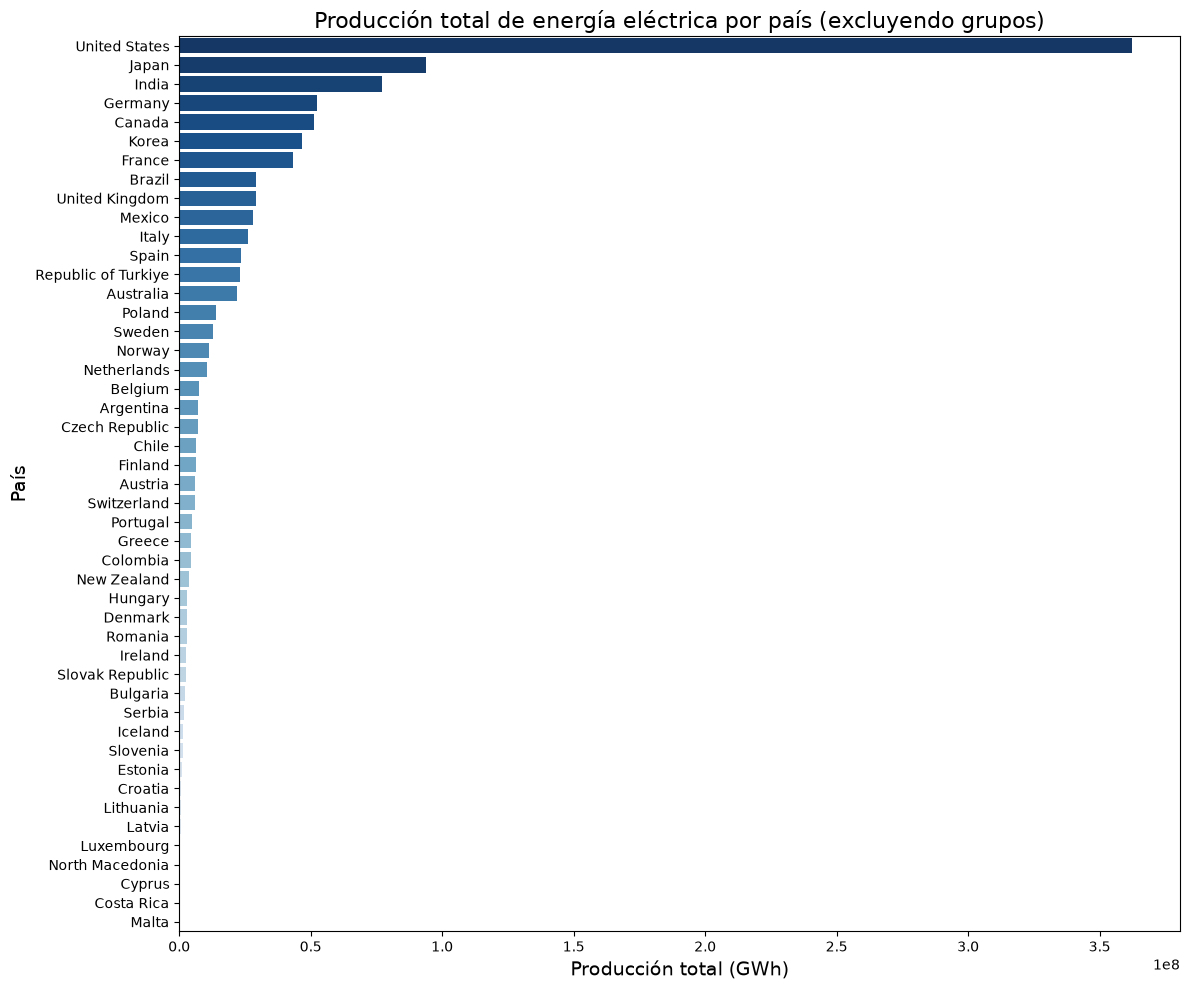

In [68]:
#Grafico de toda la energia producida

plt.figure(figsize=(12,10))

sns.barplot(
    data=energy_total,
    x='VALUE',
    y='COUNTRY',
    palette='Blues_r'
)

plt.title("Producción total de energía eléctrica por país (excluyendo grupos)", fontsize=16)
plt.xlabel("Producción total (GWh)", fontsize=14)
plt.ylabel("País", fontsize=14)

plt.tight_layout()
plt.show()


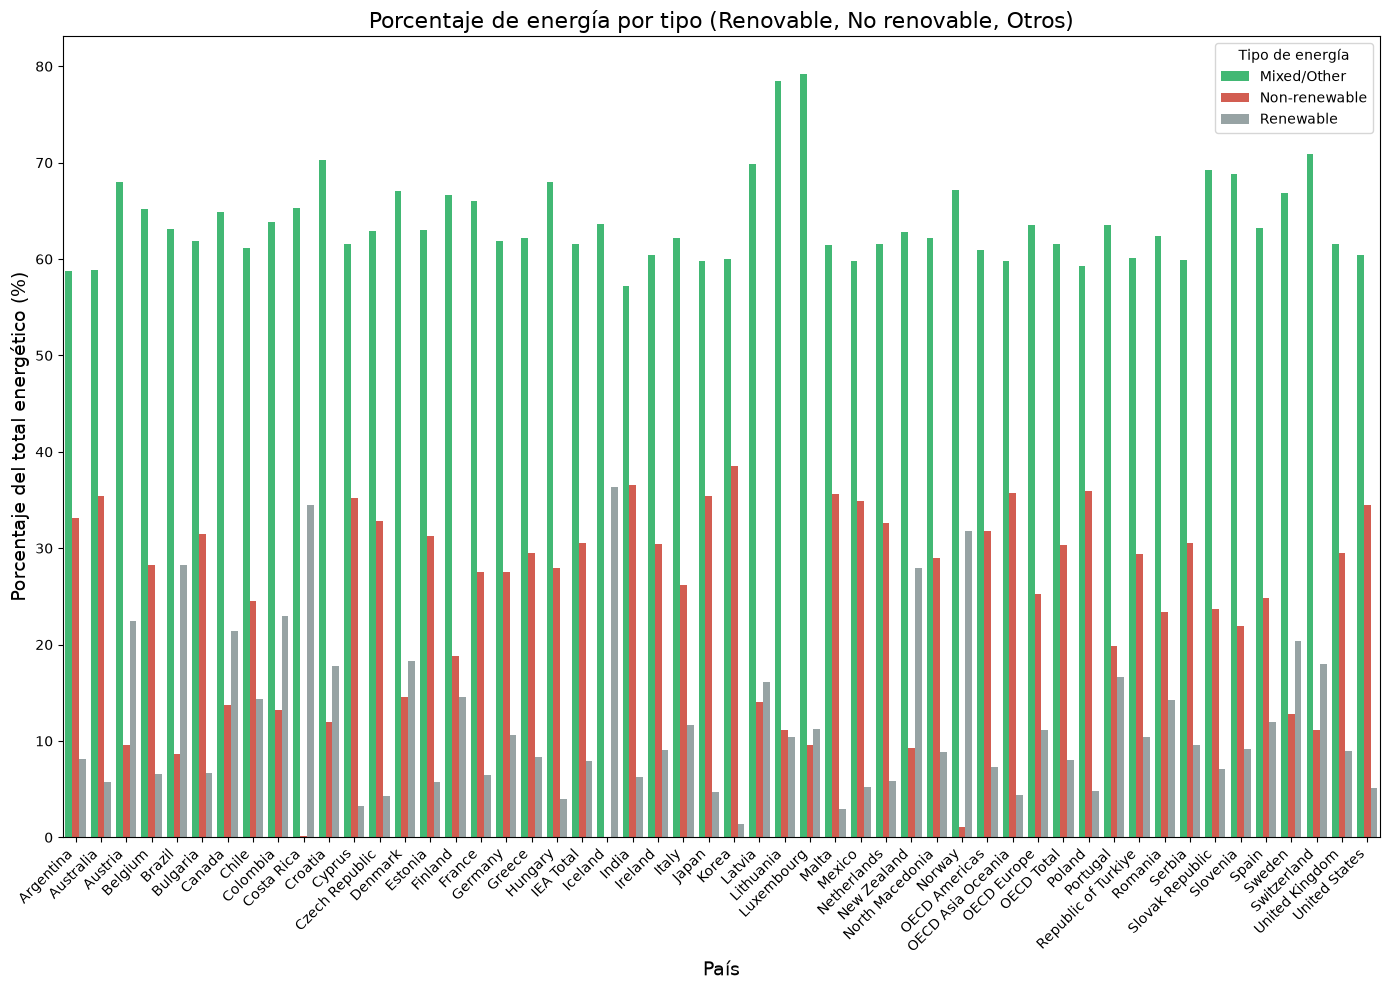

In [71]:
#Porcentajes de segun tipo de energia total

energy_by_type = df.groupby(['COUNTRY', 'RENEWABLE'])['VALUE'].sum().reset_index()

energy_total = df.groupby('COUNTRY')['VALUE'].sum().reset_index()
energy_total = energy_total.rename(columns={'VALUE': 'TOTAL_ENERGY'})


merged = energy_by_type.merge(energy_total, on='COUNTRY')

merged['PCT'] = (merged['VALUE'] / merged['TOTAL_ENERGY']) * 100

plt.figure(figsize=(14,10))

sns.barplot(
    data=merged,
    x='COUNTRY',
    y='PCT',
    hue='RENEWABLE',
    palette=['#2ecc71', '#e74c3c', '#95a5a6']  # verde, rojo, gris
)

plt.title("Porcentaje de energía por tipo (Renovable, No renovable, Otros)", fontsize=16)
plt.xlabel("País", fontsize=14)
plt.ylabel("Porcentaje del total energético (%)", fontsize=14)

plt.xticks(rotation=45, ha='right')
plt.legend(title="Tipo de energía")

plt.tight_layout()
plt.show()
